In [2]:
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
data = pd.read_excel('values.xlsx', index_col=0)
data

,ULCF (2507),LCF (2116),HCF (1357),UHCF (1150)
1,5492.0,16020,223160,377851
2,5237.0,17319,306609,495734
3,5319.0,21645,237735,458912
4,4787.0,18846,93008,441583
5,NaN,17919,114563,457023
6,NaN,9614,202298,441768


In [4]:
torques = [int(re.search(r'\((\d+)\)', s).group(1)) for s in list(data.columns)]
torques

[2507, 2116, 1357, 1150]


El par alternate se calcula como: 

$ Ta​=\frac{Tmax​−Tmin​​}{2}$

$T = C \cdot N^{-k}$

Tomando logaritmos:

$\log(T) = \log(C) - k\log(N)$

Considerando la ecuación de una recta:

$y = mx + b$

se identifican los siguientes términos:

$y = \log(T)$

$x = \log(N)$

$m = -k$

$b = \log(C)$

Por tanto, al representar experimentalmente $\log(T)$ frente a $\log(N)$, los datos deben alinearse aproximadamente sobre una recta cuya pendiente es $-k$ y cuya ordenada en el origen es $\log(C)$.

Una vez ajustada la recta mediante regresión lineal:

$y = mx + b$

los parámetros de la ecuación original se obtienen como:

$k = -m$

y

$C = 10^{\,b}$
si se emplean logaritmos en base 10.

Finalmente, la ecuación ajustada de la curva T-N queda:

$T = C \cdot N^{-k}$

T = 11514.43 * N^(-0.1762)
R² = 0.9976


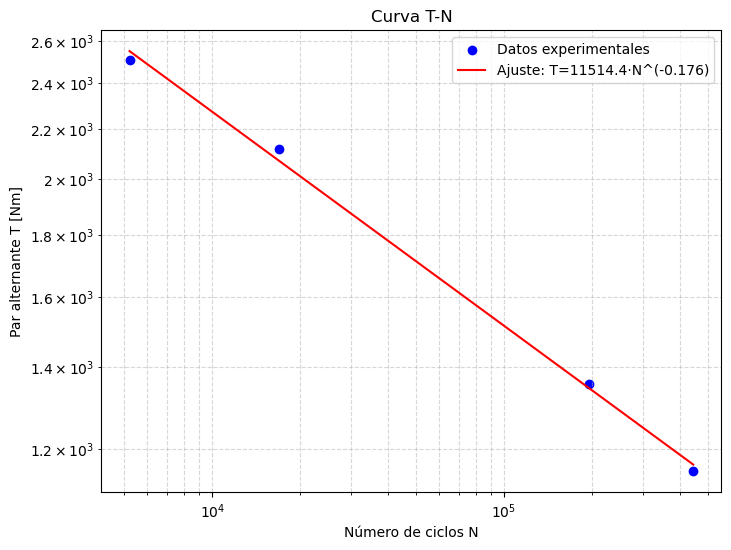

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

N = np.array(list(data.mean()))
T = np.array(torques)

# Ajuste
x = np.log10(N)
y = np.log10(T)

res = linregress(x, y)

k = -res.slope
C = 10**res.intercept

print(f"T = {C:.2f} * N^(-{k:.4f})")
print(f"R² = {res.rvalue**2:.4f}")

# Curva ajustada
N_fit = np.logspace(np.log10(min(N)),
                    np.log10(max(N)),
                    200)

T_fit = C * N_fit**(-k)

# Gráfica
plt.figure(figsize=(8,6))

plt.scatter(N, T, color='blue', label='Datos experimentales')
plt.plot(N_fit, T_fit, color='red',
         label=f'Ajuste: T={C:.1f}·N^(-{k:.3f})')

plt.xscale('log')
plt.yscale('log')

plt.xlabel('Número de ciclos N')
plt.ylabel('Par alternante T [Nm]')
plt.title('Curva T-N')
plt.grid(True, which='both', ls='--', alpha=0.5)
plt.legend()

plt.show()

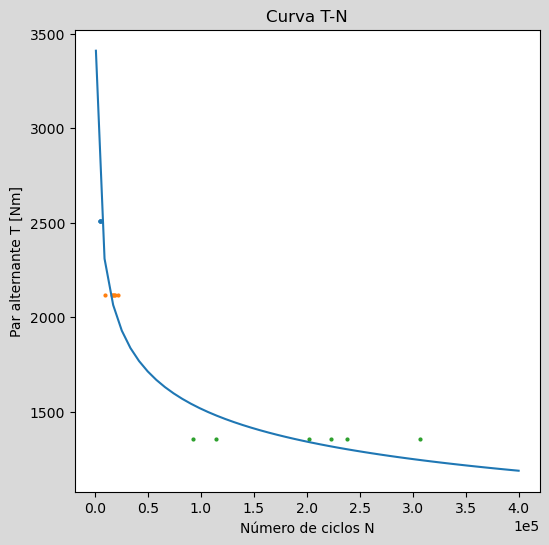

In [6]:
f, ax = plt.subplots(figsize=(6,6), facecolor='.85')

Ns = np.linspace(1000, 400000)

T_fit = C * Ns**(-k)


for i in range(3):
    sc = ax.scatter(data.iloc[:,i],
               [torques[i]] * 6,
               s=4)

    color = sc.get_facecolor()[0]


plt.plot(Ns, T_fit)
ax.ticklabel_format(style='sci', axis='x', scilimits=(0,0))

ax.set_xlabel('Número de ciclos N')
ax.set_ylabel('Par alternante T [Nm]')
ax.set_title('Curva T-N')

plt.show()





-10%     | T =    1350 Nm | N =     192470 ciclos | ΔN = +81.9%
Nominal  | T =    1500 Nm | N =     105832 ciclos | ΔN = +0.0%
+10%     | T =    1650 Nm | N =      61610 ciclos | ΔN = -41.8%


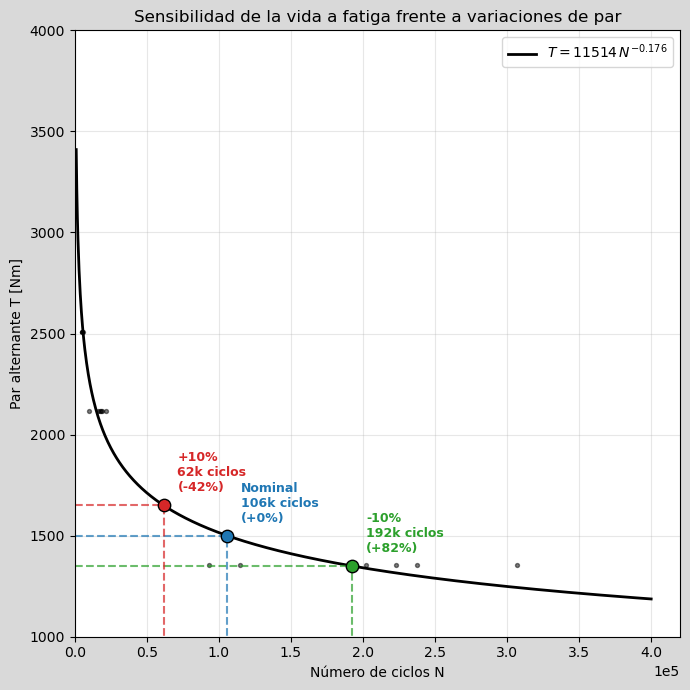

In [7]:
f, ax = plt.subplots(figsize=(7, 7), facecolor='.85')

# Datos experimentales
for i in range(3):
    ax.scatter(
        data.iloc[:, i],
        [torques[i]] * 6,
        s=8,
        color='k',
        alpha=.5
    )

# Curva ajustada
Ns = np.linspace(1e3, 4e5, 1000)
T_fit = C * Ns**(-k)

ax.plot(
    Ns,
    T_fit,
    color='k',
    lw=2,
    label=fr'$T = {C:.0f}\,N^{{-{k:.3f}}}$'
)

# Caso nominal
T0 = 1500
N0 = (C / T0)**(1 / k)

casos = [
    ('-10%', 0.90*T0, 'tab:green'),
    ('Nominal', 1.00*T0, 'tab:blue'),
    ('+10%', 1.10*T0, 'tab:red')
]

for label, T, color in casos:

    N = (C / T)**(1 / k)

    delta = 100 * (N/N0 - 1)

    print(
        f'{label:8s} | '
        f'T = {T:7.0f} Nm | '
        f'N = {N:10.0f} ciclos | '
        f'ΔN = {delta:+.1f}%'
    )

    # Líneas auxiliares
    ax.plot(
        [N, N],
        [0, T],
        '--',
        color=color,
        alpha=.7
    )

    ax.plot(
        [0, N],
        [T, T],
        '--',
        color=color,
        alpha=.7
    )

    # Punto sobre la curva
    ax.scatter(
        N,
        T,
        color=color,
        s=80,
        edgecolor='k',
        zorder=20
    )

    # Anotación
    ax.annotate(
        f'{label}\n{N/1000:.0f}k ciclos\n({delta:+.0f}%)',
        xy=(N, T),
        xytext=(10, 10),
        textcoords='offset points',
        color=color,
        fontsize=9,
        weight='bold'
    )

ax.set_xlim(left=0)
ax.set_ylim(1000, 4000)

ax.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))

ax.set_xlabel('Número de ciclos N')
ax.set_ylabel('Par alternante T [Nm]')
ax.set_title('Sensibilidad de la vida a fatiga frente a variaciones de par')

ax.grid(True, alpha=.3)
ax.legend()
plt.tight_layout()
plt.show()

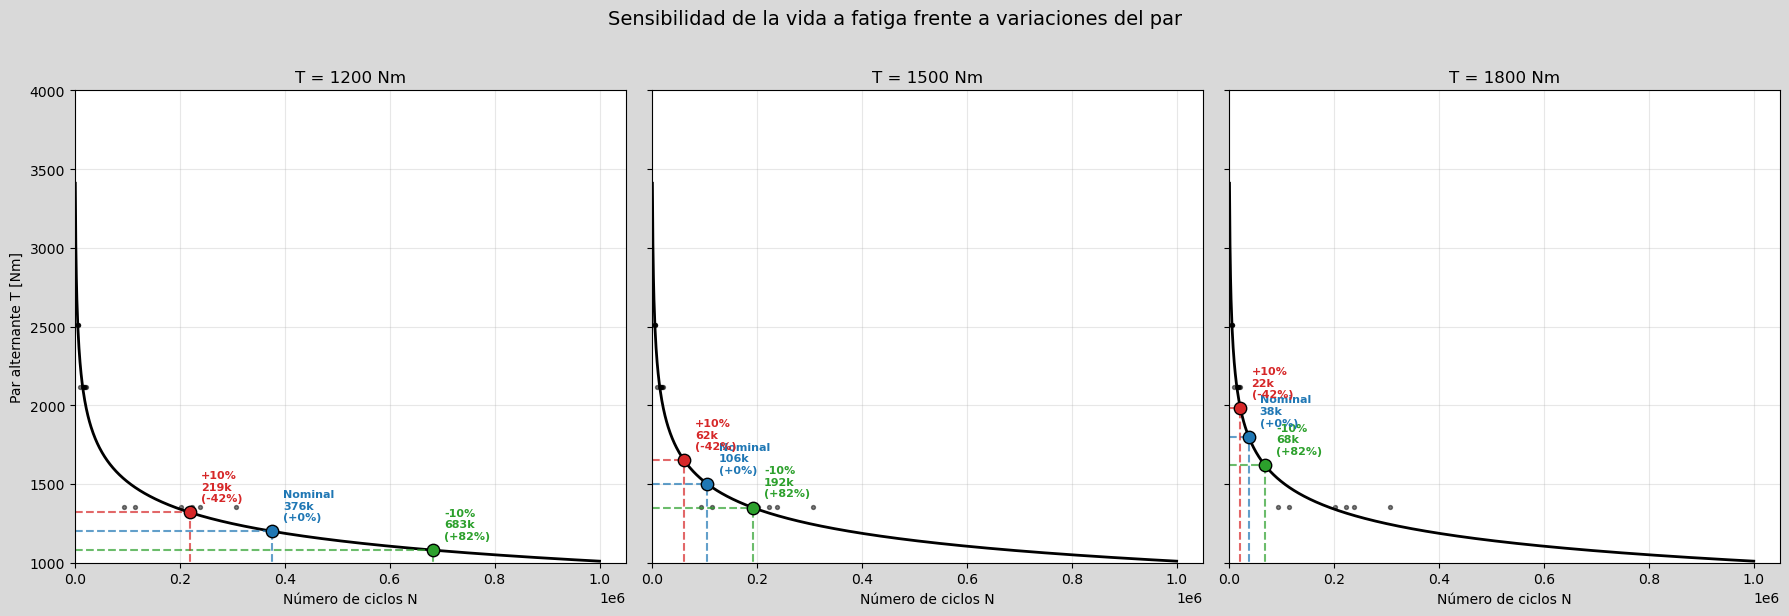

In [21]:
T0s = [1200, 1500, 1800]

# Figura con 3 subplots en una fila
f, axs = plt.subplots(
    1, 3,
    figsize=(18, 6),
    facecolor='.85',
    sharex=True,
    sharey=True
)

Ns = np.linspace(1e3, 1e6, 1000)
T_fit = C * Ns**(-k)

for ax, T0 in zip(axs, T0s):

    N0 = (C / T0)**(1 / k)

    # Datos experimentales
    for i in range(3):
        ax.scatter(
            data.iloc[:, i],
            [torques[i]] * 6,
            s=8,
            color='k',
            alpha=.5
        )

    # Curva ajustada
    ax.plot(
        Ns,
        T_fit,
        color='k',
        lw=2,
        label=fr'$T = {C:.0f}N^{{-{k:.3f}}}$'
    )

    casos = [
        ('-10%', 0.90*T0, 'tab:green'),
        ('Nominal', 1.00*T0, 'tab:blue'),
        ('+10%', 1.10*T0, 'tab:red')
    ]

    for label, T, color in casos:

        N = (C / T)**(1 / k)
        delta = 100 * (N / N0 - 1)

        # Líneas auxiliares
        ax.plot(
            [N, N],
            [0, T],
            '--',
            color=color,
            alpha=.7
        )

        ax.plot(
            [0, N],
            [T, T],
            '--',
            color=color,
            alpha=.7
        )

        # Punto
        ax.scatter(
            N,
            T,
            color=color,
            s=80,
            edgecolor='k',
            zorder=20
        )

        # Texto
        ax.annotate(
            f'{label}\n{N/1000:.0f}k\n({delta:+.0f}%)',
            xy=(N, T),
            xytext=(8, 8),
            textcoords='offset points',
            color=color,
            fontsize=8,
            weight='bold'
        )

    ax.set_title(f'T = {T0:.0f} Nm')
    ax.grid(alpha=.3)
    ax.ticklabel_format(style='sci', axis='x', scilimits=(0, 0))
    ax.set_xlim(left=0)
    ax.set_ylim(1000, 4000)

# Etiquetas comunes
axs[0].set_ylabel('Par alternante T [Nm]')

for ax in axs:
    ax.set_xlabel('Número de ciclos N')

f.suptitle(
    'Sensibilidad de la vida a fatiga frente a variaciones del par',
    fontsize=14,
    y=1.02
)

plt.tight_layout()
plt.show()

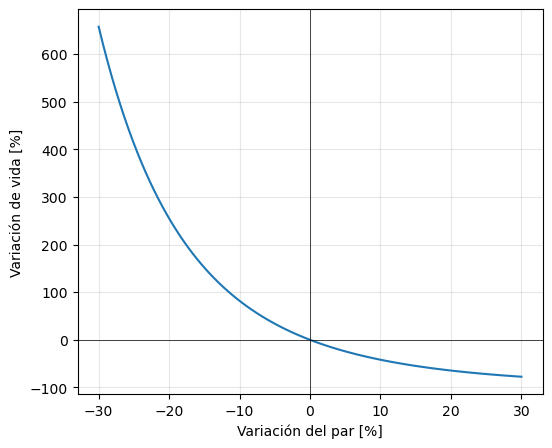

In [16]:
dT = np.linspace(-0.3, 0.3, 100)

dN = 100 * ((1 + dT)**(-1/k) - 1)

plt.figure(figsize=(6,5))
plt.plot(dT*100, dN)
plt.axhline(0, color='k', lw=.5)
plt.axvline(0, color='k', lw=.5)

plt.xlabel('Variación del par [%]')
plt.ylabel('Variación de vida [%]')
plt.grid(alpha=.3)
plt.show()